In [1]:
# Imports and paths

import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "notebooks" else cwd

DATA_PATH = PROJECT_ROOT / "data" / "cleaned" / "adult_cleaned.csv"
RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
REPORT_DIR = PROJECT_ROOT / "report"

for folder in [RESULTS_DIR, FIGURES_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH, dtype={"zip_code": "string"})
df = df.dropna(subset=["income"]).copy()
df["income"] = df["income"].astype(str).str.strip()

print("Dataset shape:", df.shape)

Dataset shape: (32561, 16)


In [2]:
# Recreate the baseline split and preprocessing

X = df.drop(columns=["income"])
y = df["income"]

numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "string", "category", "bool"]
).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

In [3]:
# Train the Random Forest baseline

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_pipeline.fit(X_train, y_train)

print("Random Forest baseline trained.")

Random Forest baseline trained.


In [4]:
# Extract feature importance
# Get encoded feature names and importances

fitted_preprocessor = rf_pipeline.named_steps["preprocessor"]
rf_model = rf_pipeline.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
importances = rf_model.feature_importances_

importance_df = pd.DataFrame({
    "encoded_feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False).reset_index(drop=True)

display(importance_df.head(20).round(6))

,encoded_feature,importance
0,numeric__age,0.069865
1,numeric__capital_gain,0.062153
2,numeric__fnlwgt,0.054708
3,numeric__hours_per_week,0.044508
4,categorical__marital_status_Married-civ-spouse,0.042074
5,numeric__education_num,0.037782
6,categorical__relationship_Husband,0.029035
7,categorical__marital_status_Never-married,0.025850
8,numeric__capital_loss,0.019384
9,categorical__occupation_Exec-managerial,0.016342


In [5]:
# Aggregate importance to original columns

def get_original_column(encoded_name):
    if encoded_name.startswith("numeric__"):
        return encoded_name.replace("numeric__", "", 1)

    if encoded_name.startswith("categorical__"):
        remaining = encoded_name.replace("categorical__", "", 1)
        return next(
            (col for col in categorical_features
             if remaining.startswith(col + "_")),
            remaining
        )

    return encoded_name

importance_df["original_feature"] = (
    importance_df["encoded_feature"].apply(get_original_column)
)

grouped_importance = (
    importance_df.groupby("original_feature", as_index=False)["importance"]
    .sum()
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

display(grouped_importance.round(6))

,original_feature,importance
0,zip_code,0.364512
1,marital_status,0.080276
2,age,0.069865
3,relationship,0.066412
4,capital_gain,0.062153
5,occupation,0.061818
6,education,0.061802
7,fnlwgt,0.054708
8,hours_per_week,0.044508
9,education_num,0.037782


In [6]:
# Save the feature-importance results

importance_df.to_csv(
    RESULTS_DIR / "feature_importance.csv",
    index=False
)

grouped_importance.to_csv(
    RESULTS_DIR / "feature_importance_by_column.csv",
    index=False
)

print("Saved encoded importance and grouped importance.")

Saved encoded importance and grouped importance.


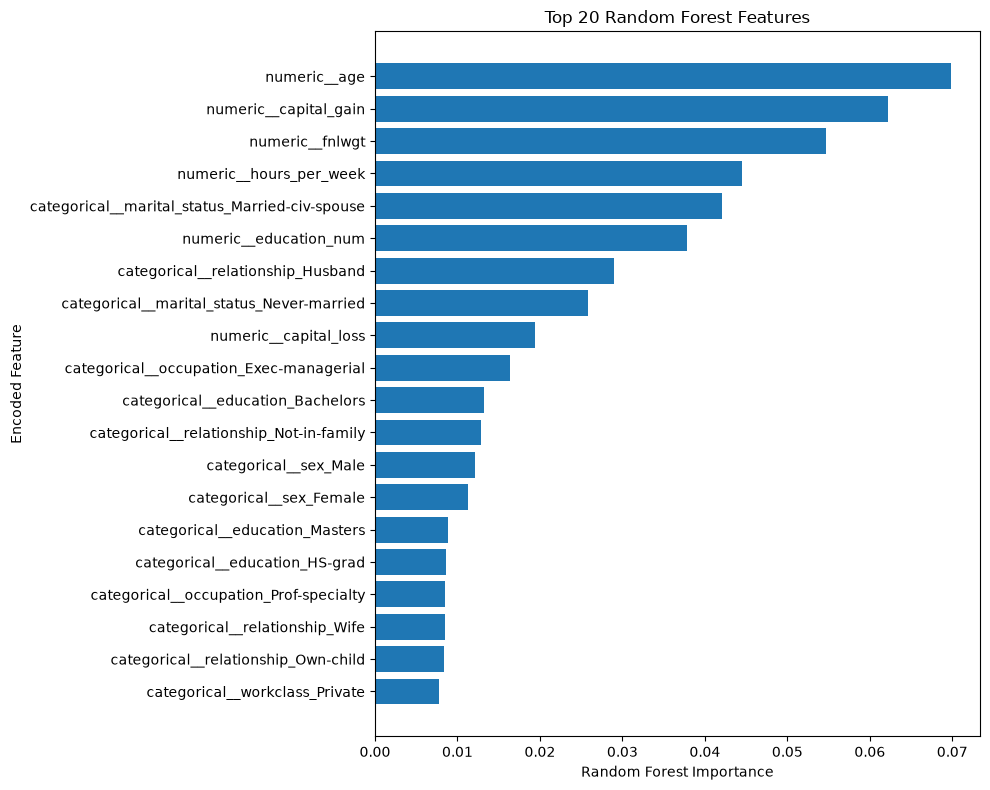

In [7]:
# Create the chart
# Plot the top 20 encoded features

top_features = importance_df.head(20).sort_values("importance")

plt.figure(figsize=(10, 8))
plt.barh(top_features["encoded_feature"], top_features["importance"])
plt.xlabel("Random Forest Importance")
plt.ylabel("Encoded Feature")
plt.title("Top 20 Random Forest Features")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "feature_importance.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

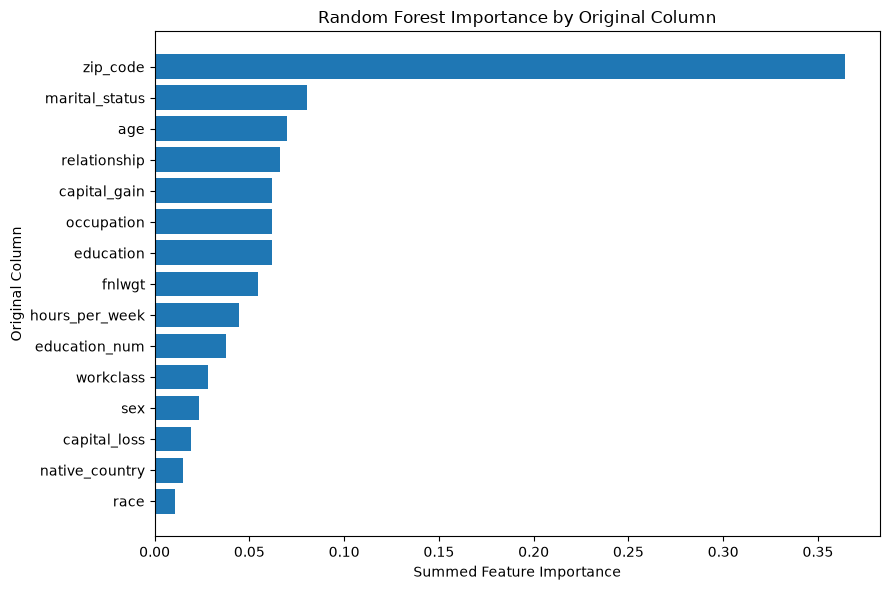

In [8]:
# Plot importance by original column

top_columns = grouped_importance.head(15).sort_values("importance")

plt.figure(figsize=(9, 6))
plt.barh(top_columns["original_feature"], top_columns["importance"])
plt.xlabel("Summed Feature Importance")
plt.ylabel("Original Column")
plt.title("Random Forest Importance by Original Column")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "feature_importance_by_column.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

In [9]:
# Compare importance with planned anonymization
# Identify relevant columns

planned_anonymization_columns = [
    "age",
    "zip_code",
    "native_country",
    "occupation",
    "marital_status",
    "education",
    "sex",
    "race"
]

comparison_df = grouped_importance.copy()

comparison_df["planned_for_anonymization"] = (
    comparison_df["original_feature"].isin(
        planned_anonymization_columns
    )
)

display(
    comparison_df.sort_values("importance", ascending=False).round(6)
)

comparison_df.to_csv(
    RESULTS_DIR / "importance_anonymization_comparison.csv",
    index=False
)

,original_feature,importance,planned_for_anonymization
0,zip_code,0.364512,True
1,marital_status,0.080276,True
2,age,0.069865,True
3,relationship,0.066412,False
4,capital_gain,0.062153,False
5,occupation,0.061818,True
6,education,0.061802,True
7,fnlwgt,0.054708,False
8,hours_per_week,0.044508,False
9,education_num,0.037782,False
